In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Reconstrucción del dataset del Tema 9
datos = {
    'temperatura_c': [18.5, 22.0, 24.5, np.nan, 16.0, 14.2, 12.8, 21.5, 17.8, 19.2],
    'humedad_pct': [65, 58, 72, 80, 50, 68, 45, 60, 62, 70],
    'precipitacion_mm': [12.4, 5.1, 8.3, 15.0, 2.0, 18.5, 1.2, 6.0, 9.4, 14.1],
    'altitud_m': [3399, 2972, 2870, 2792, 3550, 3660, 3928, 2925, 3337, 2906]
}
estaciones = ['Cusco', 'Pisaq', 'Urubamba', 'Ollantaytambo', 'Sicuani', 'Santo Tomás', 'Espinar', 'Calca', 'Anta', 'Paucartambo']

df = pd.DataFrame(datos, index=estaciones)
num_cols = ['temperatura_c', 'humedad_pct', 'precipitacion_mm', 'altitud_m']
df_clean = df[num_cols].fillna(df[num_cols].median())

# Matriz de correlación de Pearson
corr = df_clean.corr()
print(corr.round(4))

                  temperatura_c  humedad_pct  precipitacion_mm  altitud_m
temperatura_c            1.0000       0.4370           -0.0132    -0.8578
humedad_pct              0.4370       1.0000            0.8253    -0.6787
precipitacion_mm        -0.0132       0.8253            1.0000    -0.2495
altitud_m               -0.8578      -0.6787           -0.2495     1.0000


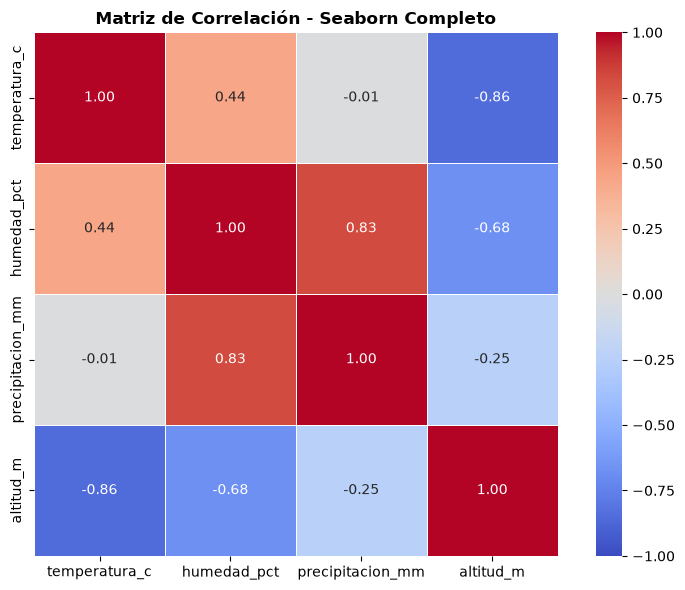

In [3]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, annot=True, fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación - Seaborn Completo', fontweight='bold')
plt.tight_layout()
plt.savefig('heatmap_seaborn.png', dpi=300)
plt.show()

Celdas visibles: 6


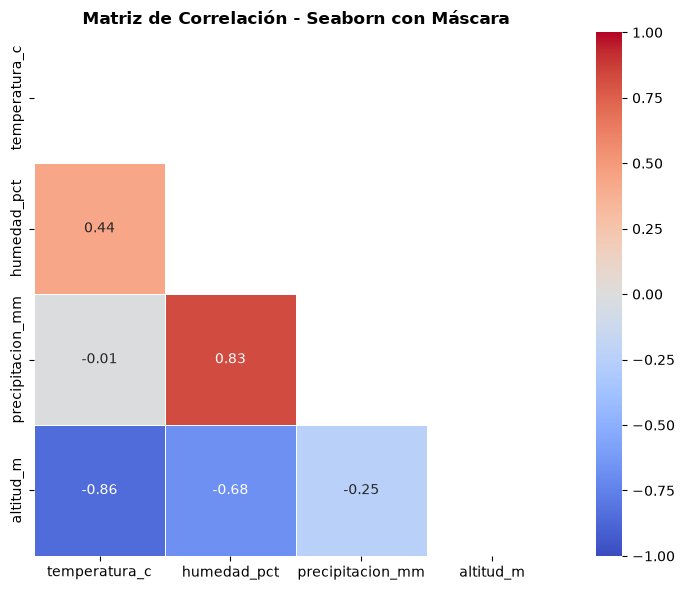

In [4]:
mascara = np.triu(np.ones_like(corr, dtype=bool))
celdas_visibles = (~mascara).sum().sum()
print("Celdas visibles:", celdas_visibles)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mascara, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, annot=True, fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación - Seaborn con Máscara', fontweight='bold')
plt.tight_layout()
plt.savefig('heatmap_seaborn_mascara.png', dpi=300)
plt.show()